# Map tritium production and neutron spectra in breeder

<!-- index:description -->
Map tritium production and neutron spectra in a concentric-spheres model.
<!-- /index:description -->

<!-- generated:structure -->
```text
Map tritium production and neutron spectra in breeder
├── 0. Cross sections
├── 1. Materials
├── 2. Geometry
├── 3. Mean free paths
├── 4. Settings (with source)
├── 5. Tallies
├── 6. Ready and plot
├── 7. Run
└── 8. Output
    ├── Li7_(n,Xt)_convergence
    ├── (n,Xt)
    ├── Neutron fluence
    ├── Energy-integrated radial contributions per spherical shell
    └── Neutron energy spectrum
        ├── First wall (EUROFER)
        └── Breeder (PbLi)
```
<!-- /generated:structure -->

Based on a simple, three-cell concentric-spheres model of a breeder
blanket, this notebook follows a think-aloud process of building an
initial OpenMC simulation. Cross sections and mean free paths are
considered alongside the usual workflow of defining materials,
geometry, settings, and tallies.

The simulation tallies neutron fluence as a function of radius and
energy, and tritium production in radial shells. Radial bins are
arranged so that each lies within a homogeneous material.

The simulation also demonstrates the use of an OpenMC tally trigger
to terminate a run once a specified uncertainty criterion is met,
somewhat analogous to early stopping in machine learning.

The radii `R_VESSEL`, `FW_THICK`, and `BB_THICK` are adopted from the
[Fusion Energy Neutronics Workshop](https://fusion-energy.github.io/neutronics-workshop/tasks/task_05_CSG_cell_tally_TBR/1_example_tritium_production.html).

In [1]:
import re
from pathlib import Path

import openmc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from openmc_workbench_config import DATA_ROOT

xs_xml = DATA_ROOT / 'endf-b8.1' / 'cross_sections.xml'
openmc.config['cross_sections'] = xs_xml

SOURCE_eV = 14e6

R_VESSEL = 500.
FW_THICK = 10.
BB_THICK = 100.

output_dir = Path('output_0')
output_dir.mkdir(exist_ok=True)

## 0. Cross sections

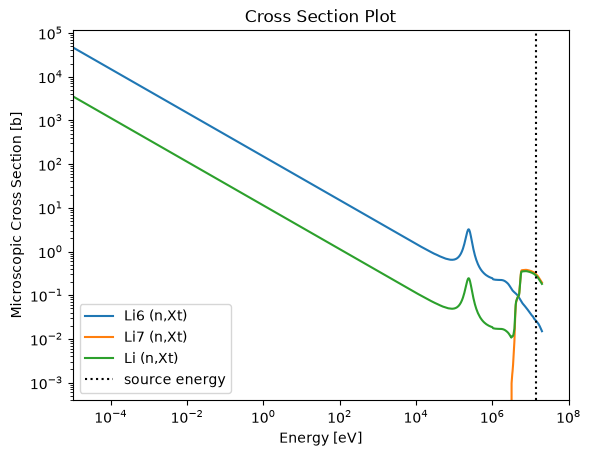

In [2]:
fig = openmc.plotter.plot_xs(
    reactions = {
        'Li6': ['(n,Xt)'],
        'Li7': ['(n,Xt)'],
        'Li': ['(n,Xt)'],
    }
)
ax = fig.axes[0]
ax.axvline(SOURCE_eV, label='source energy',  ls=':', color='k')
ax.set_xlim(right=1e8)
ax.legend()

## 1. Materials

The first wall is represented by a reduced-activation
ferritic/martensitic steel, EUROFER97  
([EUROFER97 composition](https://www.mdpi.com/2076-3417/11/22/10598), [EUROFER97 density](https://scientific-publications.ukaea.uk/wp-content/uploads/UKAEA-CCFE-PR2183.PDF)).

In [3]:
# https://docs.openmc.org/en/stable/pythonapi/generated/openmc.Material.html
mats_df = pd.DataFrame(columns=[
    'name', 'element', 'percent', 'percent_type',
    'enrichment', 'enrichment_target', 'enrichment_type',
])

breeder_at = {
    'Pb': 84.2,
    'Li': 15.8,
}

eurofer_wt = {
    'Cr': 8.93,
    'W': 1.07,
    'Mn': 0.47,
    'V': 0.20,
    'Ta': 0.14,
    'C': 0.12,
    'Ti': 0.009,
    'N': 0.018,
}
eurofer_wt['Fe'] = 100 - sum(eurofer_wt.values())

for name, composition, percent_type in [
    ('breeder', breeder_at, 'ao'),
    ('eurofer97', eurofer_wt, 'wo'),
]:
    for element, percent in composition.items():
        enrichment = 50 if name == 'breeder' and element == 'Li' else None
        mats_df.loc[len(mats_df)] = [
            name, element, percent, percent_type,
            enrichment,
            'Li6' if enrichment is not None else None,
            'ao' if enrichment is not None else None,
        ]

mats_df

,name,element,percent,percent_type,enrichment,enrichment_target,enrichment_type
0,breeder,Pb,84.200,ao,None,None,None
1,breeder,Li,15.800,ao,50,Li6,ao
2,eurofer97,Cr,8.930,wo,None,None,None
3,eurofer97,W,1.070,wo,None,None,None
4,eurofer97,Mn,0.470,wo,None,None,None
5,eurofer97,V,0.200,wo,None,None,None
6,eurofer97,Ta,0.140,wo,None,None,None
7,eurofer97,C,0.120,wo,None,None,None
8,eurofer97,Ti,0.009,wo,None,None,None
9,eurofer97,N,0.018,wo,None,None,None


In [4]:
mats_dic = {}
for name, dat in mats_df.groupby('name'):
    mats_dic[name] = openmc.Material(name=name)

    for _, row in dat.drop(columns='name').iterrows():
        mats_dic[name].add_element(**row.dropna().to_dict())

mats_dic['breeder'].set_density('atom/b-cm', 3.2720171e-2)
mats_dic['eurofer97'].set_density('g/cm3', 7.78)
mats_dic

{'breeder': Material
 	ID             =	1
 	Name           =	breeder
 	Temperature    =	None
 	Density        =	0.032720171 [atom/b-cm]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	Pb204          =	1.1788       [ao]
 	Pb206          =	20.2922      [ao]
 	Pb207          =	18.6082      [ao]
 	Pb208          =	44.1208      [ao]
 	Li6            =	7.9          [ao]
 	Li7            =	7.9          [ao],
 'eurofer97': Material
 	ID             =	2
 	Name           =	eurofer97
 	Temperature    =	None
 	Density        =	7.78 [g/cm3]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	Cr50           =	0.3727102154087453 [wo]
 	Cr52           =	7.474353057975188 [wo]
 	Cr53           =	0.8638513029076939 [wo]
 	Cr54           =	0.21908542370837283 [wo]
 	W180           =	0.001256795818590312 [wo]
 	W182           =	0.2806294293962744 [wo]
 	W183           =	0.15237444705438208 [wo]
 	W184           =	0.328

In [5]:
model = {}
model['materials'] = openmc.Materials(mats_dic.values())

## 2. Geometry

In [6]:
geom_df = pd.DataFrame(
    columns=['radius_cm', 'boundary_type', 'region', 'mats']
)
geom_df.loc['vessel_inner'] = [R_VESSEL, None, '-vessel_inner', None]
geom_df.loc['first_wall'] = [
    R_VESSEL + FW_THICK, None, '-first_wall & +vessel_inner', 'eurofer97'
]
geom_df.loc['breeder_blanket'] = [
    R_VESSEL + FW_THICK + BB_THICK,
    'vacuum', '+first_wall & -breeder_blanket', 'breeder',
]
geom_df

,radius_cm,boundary_type,region,mats
vessel_inner,500.0,None,-vessel_inner,None
first_wall,510.0,None,-first_wall & +vessel_inner,eurofer97
breeder_blanket,610.0,vacuum,+first_wall & -breeder_blanket,breeder


In [7]:
# Ensure that all surfaces referenced in region expressions are 
# defined in geom_df.index.
assert all(
    name in geom_df.index
    for region in geom_df['region']
    for name in re.findall(r'\b\w+\b', region)
)

In [8]:
sphere = {}
for name, dat in geom_df.iterrows():
    sphere[name] = openmc.Sphere(
        r=dat['radius_cm'],
        **dat[['boundary_type']].dropna().to_dict()
    )

In [9]:
# Convert named surface expressions into OpenMC regions.
# https://docs.openmc.org/en/stable/pythonapi/generated/openmc.Region.html

surfaces = {s.id: s for s in sphere.values()}

def str2region(string):
    for name, surface in sphere.items():
        string = string.replace(name, str(surface.id))

    string = string.replace('&', ' ')

    return openmc.Region.from_expression(string, surfaces)

geom = {}
for name, dat in geom_df.iterrows():
    geom[name] = openmc.Cell(
        name=name,
        region=str2region(dat['region']),
        fill=mats_dic.get(dat['mats'])
    )

model['geometry'] = openmc.Geometry(geom.values())

## 3. Mean free paths

In [10]:
for name, mat in mats_dic.items():
    geom_df.loc[geom_df['mats'] == name, 'mfp@14MeV_cm'] = (
        mat.mean_free_path(SOURCE_eV)
    )

geom_df

,radius_cm,boundary_type,region,mats,mfp@14MeV_cm
vessel_inner,500.0,None,-vessel_inner,None,NaN
first_wall,510.0,None,-first_wall & +vessel_inner,eurofer97,4.627315
breeder_blanket,610.0,vacuum,+first_wall & -breeder_blanket,breeder,6.500664


## 4. Settings (with source)

In [11]:
model['settings'] = openmc.Settings()
model['settings'].seed = 77
model['settings'].batches = 5
model['settings'].particles = 10000
model['settings'].run_mode = 'fixed source'

# Adaptive stopping
model['settings'].trigger_active = True
model['settings'].trigger_max_batches = 100
model['settings'].trigger_batch_interval = 5

model['settings'].source = openmc.IndependentSource(
    space=openmc.stats.Point((0, 0, 0)),
    angle=openmc.stats.Isotropic(),
    energy=openmc.stats.Discrete([SOURCE_eV], [1])
)

## 5. Tallies

$^6Li + n \rightarrow \alpha + T$

$^7Li + n \rightarrow \alpha + T + n$

For this simulation, the TBR is the number of tritium nuclei
produced per source neutron.

In [12]:
cell_filter = openmc.CellFilter(geom['breeder_blanket'])

tic = R_VESSEL
toc = R_VESSEL + FW_THICK + BB_THICK
num = int(1 + (toc - tic) // 5)
r_edges = np.linspace(tic, toc, num)

# Logarithmic energy bins (eV), extending beyond the 14-MeV source.
E_edges = np.logspace(-3, np.log10(20e6), 101)

mesh_filter = openmc.MeshFilter(openmc.SphericalMesh(r_grid=r_edges))
energy_filter = openmc.EnergyFilter(E_edges)

model['tallies'] = openmc.Tallies([
    openmc.Tally(
        name='(n,Xt)',
        # Exclude vessel_inner and first_wall.
        filters=[cell_filter],
        scores=['(n,Xt)'],
        nuclides=mats_dic['breeder'].get_nuclides() + ['total'],
    ),
    openmc.Tally(
        name='Li7_(n,Xt)_convergence',
        filters=[cell_filter],
        scores=['(n,Xt)'],
        nuclides=['Li7'],
        triggers=[openmc.Trigger('rel_err', 0.01)],
    ),
    # OpenMC calls its track-length score 'flux' (particle-cm per source
    # particle). After division by volume, the result is neutron fluence
    # per history, not fluence rate; the latter also needs a source rate.
    # https://docs.openmc.org/en/stable/usersguide/tallies.html

    # Resolve neutron fluence by radius and incident energy.
    openmc.Tally(
        name='fluence_r_E',
        filters=[mesh_filter, energy_filter],
        scores=['flux'],
    ),
    # Radial bins: integrate neutron track-length and (n,Xt) production.
    openmc.Tally(
        name='fluence_n_Xt_r',
        filters=[mesh_filter],
        scores=['flux', '(n,Xt)'],
    ),
])

## 6. Ready and plot
Due to the spherical symmetry of the geometry, plotting just one
quadrant is good.

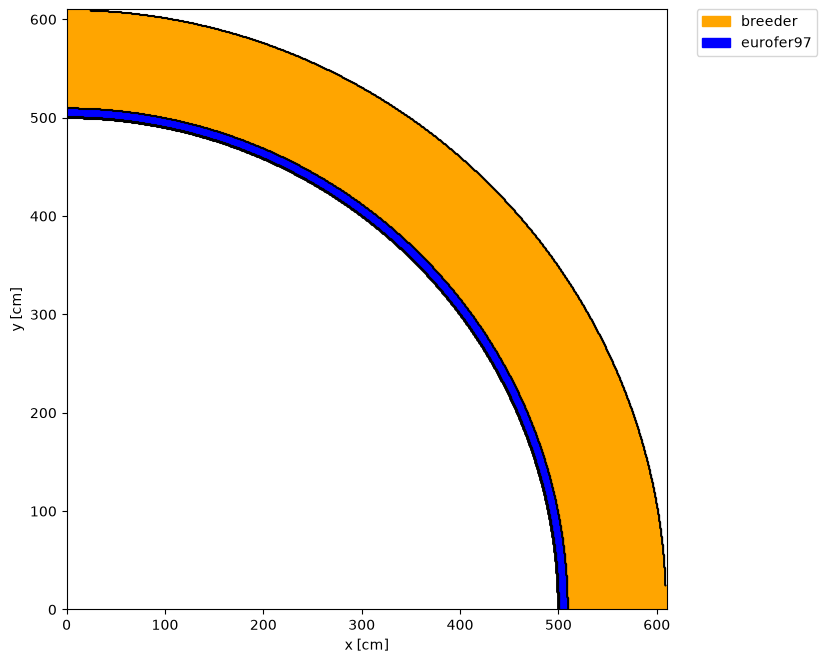

In [13]:
openmc_model = openmc.Model(**model)
colors = {
    mats_dic['breeder']: 'orange',
    mats_dic['eurofer97']: 'blue',
}

R = 610

ax = openmc_model.plot(
    basis='xy',
    origin=(R/2, R/2, 0),
    width=(R, R),
    color_by='material',
    colors=colors,
    outline=True,
    legend=True,
    pixels=(600, 600),
)

## 7. Run

In [14]:
sp_filename = openmc_model.run(cwd=output_dir)

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

## 8. Output

In [15]:
# Collect every tally in the statepoint, indexed by its name.
with openmc.StatePoint(sp_filename) as sp:
    tallies = {t.name: t for t in sp.tallies.values()}
    completed_batches = sp.current_batch

list(tallies)

['(n,Xt)', 'Li7_(n,Xt)_convergence', 'fluence_r_E', 'fluence_n_Xt_r']

### Li7_(n,Xt)_convergence

In [16]:
rel_err = tallies['Li7_(n,Xt)_convergence'].get_values(
    value='rel_err'
).item()

# The trigger definition belongs to the model, not the statepoint.
trigger_tally = next(
    t for t in openmc_model.tallies
    if t.name == 'Li7_(n,Xt)_convergence'
)
trigger_value = trigger_tally.triggers[0].threshold

rel_err, trigger_value

(0.009367305299817096, 0.01)

In [17]:
if rel_err > trigger_value:
    assert (
        completed_batches >= openmc_model.settings.trigger_max_batches
    )

### (n,Xt)

In [18]:
tallies['(n,Xt)']

Tally
	ID             =	1
	Name           =	(n,Xt)
	Filters        =	CellFilter
	Nuclides       =	Pb204 Pb206 Pb207 Pb208 Li6 Li7 total
	Scores         =	['(n,Xt)']
	Estimator      =	tracklength
	Multiply dens. =	True

In [19]:
df_n_Xt = tallies['(n,Xt)'].get_pandas_dataframe()
df_n_Xt['rel_err'] = df_n_Xt['std. dev.'] / df_n_Xt['mean'].abs()
df_n_Xt.sort_values('mean', ascending=False)

,cell,nuclide,score,mean,std. dev.,rel_err
6,3,total,"(n,Xt)",1.099886e+00,3.019845e-03,0.002746
4,3,Li6,"(n,Xt)",1.096104e+00,3.030459e-03,0.002765
5,3,Li7,"(n,Xt)",3.782180e-03,3.542883e-05,0.009367
3,3,Pb208,"(n,Xt)",7.920749e-08,7.338259e-10,0.009265
2,3,Pb207,"(n,Xt)",2.622269e-08,2.448501e-10,0.009337
0,3,Pb204,"(n,Xt)",1.963919e-08,1.838900e-10,0.009363
1,3,Pb206,"(n,Xt)",0.000000e+00,0.000000e+00,NaN


### Neutron fluence

The fluence map is normalized by spherical-shell volume and lethargy-bin width.
The second map shows relative statistical error; bins with zero
fluence are blank.

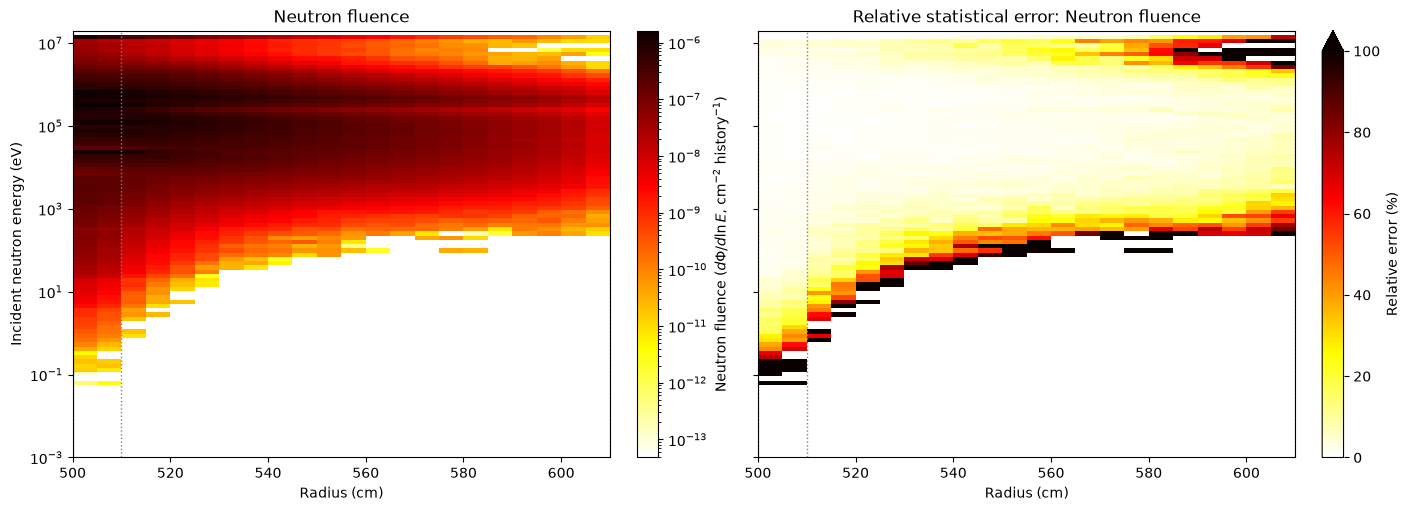

In [20]:
# Extract neutron fluence from the radius–energy tally.
fluence_tally = tallies['fluence_r_E']
mesh = fluence_tally.find_filter(openmc.MeshFilter).mesh
energy_filter = fluence_tally.find_filter(openmc.EnergyFilter)

fluence = fluence_tally.get_reshaped_data(value='mean').squeeze()
fluence_std = fluence_tally.get_reshaped_data(value='std_dev').squeeze()

volumes = mesh.volumes[:, 0, 0]
du = np.log(E_edges[1:] / E_edges[:-1])
fluence_per_lethargy = fluence / volumes[:, None] / du[None, :]

# Relative error is undefined where the mean is zero.
fluence_rel_err = np.full_like(fluence, np.nan)
np.divide(
    fluence_std, np.abs(fluence), out=fluence_rel_err,
    where=fluence != 0,
)

# Plot the fluence and its relative statistical error.
values_plot = np.ma.masked_less_equal(fluence_per_lethargy.T, 0)
err_plot = np.ma.masked_invalid(100 * fluence_rel_err.T)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5), sharex=True, sharey=True,
    layout='constrained',
)

pcm_value = axes[0].pcolormesh(
    mesh.r_grid, energy_filter.values, values_plot,
    cmap='hot_r', norm=LogNorm(), shading='auto',
)
pcm_err = axes[1].pcolormesh(
    mesh.r_grid, energy_filter.values, err_plot,
    cmap='hot_r', vmin=0, vmax=100, shading='auto',
)

for ax in axes:
    ax.set(yscale='log', xlabel='Radius (cm)')
    for r in geom_df['radius_cm']:
        ax.axvline(r, color='gray', ls=':', lw=1)

axes[0].set(title='Neutron fluence', ylabel='Incident neutron energy (eV)')
axes[1].set_title('Relative statistical error: Neutron fluence')

fig.colorbar(
    pcm_value, ax=axes[0],
    label=r'Neutron fluence ($d\Phi/d\ln E$, cm$^{-2}$ history$^{-1}$)',
)
fig.colorbar(
    pcm_err, ax=axes[1], label='Relative error (%)', extend='max',
)
plt.show()

### Energy-integrated radial contributions per spherical shell

The two profiles show neutron track-length and `(n,Xt)` production
integrated over each spherical shell, without dividing by shell volume.
The `(n,Xt)` score estimates tritium nuclei produced per source neutron;
it is not transported triton fluence.

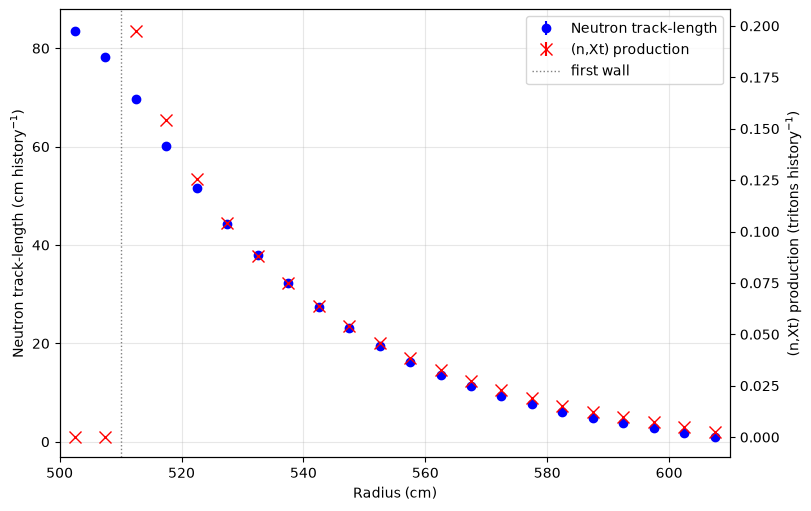

In [21]:
radial_tally = tallies['fluence_n_Xt_r']
mesh_r = radial_tally.find_filter(openmc.MeshFilter).mesh
fluence_r_tally = radial_tally.get_slice(scores=['flux'])
assert '(n,Xt)' in radial_tally.scores, radial_tally.scores
n_Xt_r_tally = radial_tally.get_slice(scores=['(n,Xt)'])

# Each score is integrated over each spherical shell and over energy.
# Do not divide by shell volume.
fluence_r = fluence_r_tally.get_reshaped_data(value='mean').squeeze()
fluence_r_std = fluence_r_tally.get_reshaped_data(value='std_dev').squeeze()
n_Xt_r = n_Xt_r_tally.get_reshaped_data(value='mean').squeeze()
n_Xt_r_std = n_Xt_r_tally.get_reshaped_data(value='std_dev').squeeze()

r_mid = (mesh_r.r_grid[:-1] + mesh_r.r_grid[1:]) / 2

fig, ax_fluence = plt.subplots(figsize=(8, 5), layout='constrained')
ax_n_Xt = ax_fluence.twinx()

fluence_profile = ax_fluence.errorbar(
    r_mid, fluence_r, yerr=fluence_r_std,
    fmt='o', ls='none',
    color='blue', ecolor='blue',
    label='Neutron track-length',
)
n_Xt_profile = ax_n_Xt.errorbar(
    r_mid, n_Xt_r, yerr=n_Xt_r_std,
    fmt='x', ls='none', ms=8,
    color='red', ecolor='red',
    label='(n,Xt) production',
)

r = geom_df.loc['first_wall', 'radius_cm']
first_wall = ax_fluence.axvline(
    r, color='gray', ls=':', lw=1, label='first wall'
)

ax_fluence.set(
    xlabel='Radius (cm)',
    ylabel='Neutron track-length (cm history$^{-1}$)',
    xlim=(mesh_r.r_grid[0], mesh_r.r_grid[-1]),
)
ax_n_Xt.set_ylabel('(n,Xt) production (tritons history$^{-1}$)')

ax_fluence.grid(alpha=0.3)
ax_fluence.legend(
    [fluence_profile, n_Xt_profile, first_wall],
    [
        fluence_profile.get_label(),
        n_Xt_profile.get_label(),
        first_wall.get_label(),
    ],
)

### Neutron energy spectrum

#### First wall (EUROFER)

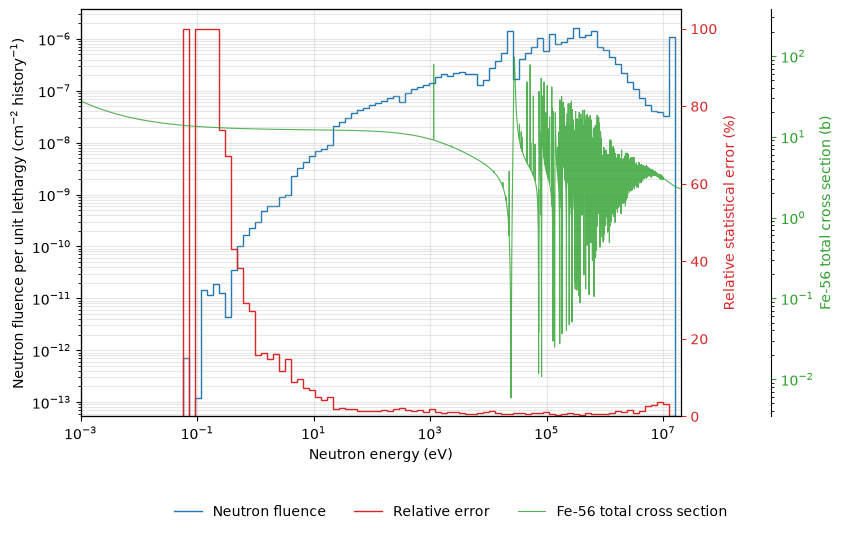

In [22]:
def plot_neutron_spectrum(r_bin, xs_E, xs, xs_label, xs_unit):
    """Plot a shell's neutron spectrum, uncertainty, and cross section."""
    spectrum = fluence_per_lethargy[r_bin, :]
    error_percent = 100 * fluence_rel_err[r_bin, :]

    fig, ax = plt.subplots(figsize=(10, 5.5))
    fig.subplots_adjust(left=0.13, right=0.73, bottom=0.23, top=0.97)
    ax_err = ax.twinx()
    ax_xs = ax.twinx()
    ax_xs.spines['right'].set_position(('outward', 65))

    fluence_curve = ax.stairs(
        np.where(spectrum > 0, spectrum, np.nan),
        E_edges, label='Neutron fluence', color='tab:blue',
    )
    error_curve = ax_err.stairs(
        error_percent, E_edges,
        label='Relative error', color='tab:red',
    )
    xs_curve, = ax_xs.plot(
        xs_E, np.where(xs > 0, xs, np.nan),
        label=xs_label, color='tab:green', lw=0.8, alpha=0.8,
    )

    ax.set(
        xscale='log', yscale='log',
        xlim=(E_edges[0], E_edges[-1]),
        xlabel='Neutron energy (eV)',
        ylabel=(
            r'Neutron fluence per unit lethargy '
            r'(cm$^{-2}$ history$^{-1}$)'
        ),
    )
    ax_err.set_ylabel('Relative statistical error (%)', color='tab:red')
    ax_err.tick_params(axis='y', colors='tab:red')
    ax_err.set_ylim(bottom=0)
    ax_xs.set_yscale('log')
    ax_xs.set_ylabel(f'{xs_label} ({xs_unit})', color='tab:green')
    ax_xs.tick_params(axis='y', colors='tab:green')
    ax.grid(which='both', alpha=0.3)

    curves = [fluence_curve, error_curve, xs_curve]
    fig.legend(
        handles=curves, labels=[c.get_label() for c in curves],
        loc='lower center', bbox_to_anchor=(0.5, 0.02),
        ncol=3, frameon=False,
    )
    plt.show()

xs_E, xs_data = openmc.plotter.calculate_cexs(
    'Fe56', ['total'], cross_sections=str(xs_xml),
)
plot_neutron_spectrum(
    0, xs_E, xs_data[0], 'Fe-56 total cross section', 'b',
)
# The jagged features in the high-energy fluence spectrum are consistent
# with resonance structure in the neutron cross sections. The relative
# statistical errors are small compared with the spectral variations.
# Note that Fe-56 is only one constituent of EUROFER97, and its
# microscopic cross section is not the total macroscopic cross section
# of the steel.

#### Breeder (PbLi)

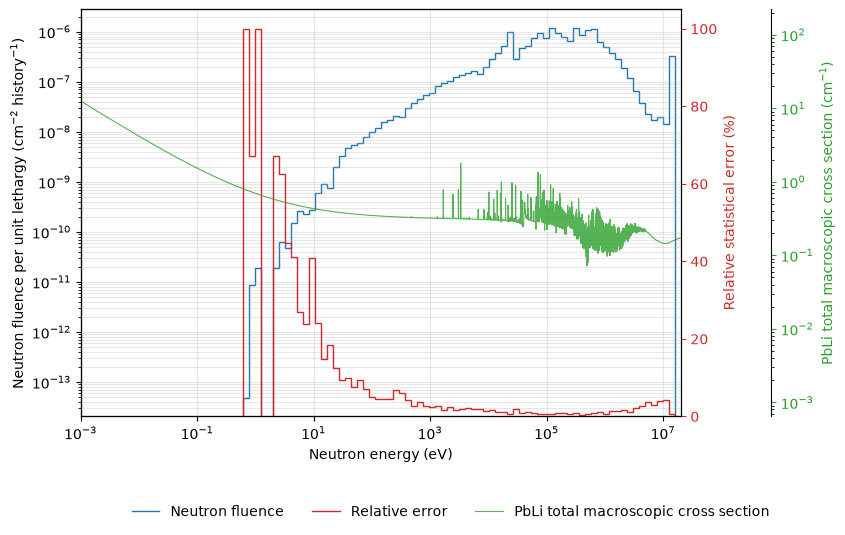

In [23]:
breeder_bin = 2
assert np.isclose(
    mesh.r_grid[breeder_bin],
    R_VESSEL + FW_THICK,
)

xs_E, xs_data = openmc.plotter.calculate_cexs(
    mats_dic['breeder'], ['total'], cross_sections=str(xs_xml),
)
plot_neutron_spectrum(
    breeder_bin, xs_E, xs_data[0],
    'PbLi total macroscopic cross section', r'cm$^{-1}$',
)